# Module 3: Data Cleaning & Preprocessing
**Project:** House Price Prediction for a Real Estate Listing Platform (Ames, Iowa)  
**Input:** `data/processed/train_augmented.csv` ($n = 1,460$) & `data/processed/test_augmented.csv` ($n = 1,459$)  
**Output:** `data/processed/train_cleaned.csv` ($n = 1,458$) & `data/processed/test_cleaned.csv` ($n = 1,459$)  
**Objective:** Resolve missing values, duplicates, inconsistent categorical labels, data-entry errors, and extreme outliers without data leakage, documenting every transformation with before/after comparisons.

In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

# Resolve project root dynamically whether run from notebooks/ or root
project_root = Path('..') if Path('../src').exists() else Path('.')
sys.path.insert(0, str(project_root / 'src'))
import data_cleaning as dc

train_path = str(project_root / 'data' / 'processed' / 'train_augmented.csv')
test_path = str(project_root / 'data' / 'processed' / 'test_augmented.csv')
output_dir = str(project_root / 'data' / 'processed')
figures_dir = str(project_root / 'figures')

results = dc.run_module3_cleaning(
    train_path=train_path,
    test_path=test_path,
    output_dir=output_dir,
    figures_dir=figures_dir,
)
clean_train = pd.read_csv(results['clean_train_path'])
clean_test = pd.read_csv(results['clean_test_path'])
print('Pipeline execution complete.')
print(f'Cleaned Train Shape: {clean_train.shape} | Cleaned Test Shape: {clean_test.shape}')

2026-11-26 12:36:23,944 [INFO] Loaded raw datasets -> Train: (1460, 94), Test: (1459, 93)
2026-11-26 12:36:28,398 [INFO] Module 3 Data Cleaning complete. Saved cleaned datasets and audit figures.


Pipeline execution complete.
Cleaned Train Shape: (1458, 94) | Cleaned Test Shape: (1459, 93)


## 1. Executive Before / After Comparison
Summary of dataset dimensions, missing cell counts, standardization updates, and distributional skew before and after Module 3 cleaning.

In [2]:
display(results['summary_comparison'])

,Metric,Before Cleaning,After Cleaning,Change / Notes
0,Training Rows,"1,460","1,458",-2 rows (removed Edwards partial-sale outliers)
1,Test Rows,"1,459","1,459",0 rows dropped (strict test-set row preservation)
2,Total Missing Cells (Train / Test),"9,824 / 9,978",0 / 0,100% resolved via structural None/0 + train-fi...
3,Exact / Primary-Key Duplicates,0 / 0,0 / 0,"Verified across full rows, Id, and feature sub..."
4,Standardized Categorical Tokens,Raw Ames codes + typos,Canonical tokens,4233 train & 4215 test cells updated
5,SalePrice Skewness (Train),1.883,1.881,Target distribution preserved without distortion
6,GrLivArea Max / Skewness (Train),"5,642 / 1.367","4,476 / 1.011",Reduced skew by 24.5% after removing 2 leverag...
7,LotArea Max / Skewness (Train),"215,245 / 12.208","53,193 / 3.814","Capped at 99.5th percentile (8 train, 2 test r..."


## 2. Duplicate Audit & Categorical Label Standardization
We verify uniqueness across exact rows, primary keys (`Id`), and feature subsets, followed by canonical standardization of property types (`BldgType`, `HouseStyle`), zoning (`MSZoning`), exterior siding (`Exterior1st`/`Exterior2nd`), and synthetic `renovation_type` tokens.

In [3]:
print('=== Duplicate Audit ===')
print(json.dumps(results['duplicate_audit'], indent=2))

print('\n=== Categorical Standardization Log ===')
display(results['categorical_log'])

=== Duplicate Audit ===
{
  "train_exact_rows": 0,
  "test_exact_rows": 0,
  "train_duplicate_ids": 0,
  "test_duplicate_ids": 0,
  "train_feature_duplicates": 0,
  "test_feature_duplicates": 0
}

=== Categorical Standardization Log ===


,column,rule,train_modified,test_modified
0,Exterior1st,Harmonize exterior siding naming across Exteri...,206,205
1,Exterior2nd,"Fix Ames typos ('Brk Cmn'->'BrkComm', 'CmentBd...",302,318
2,MSZoning,Remove parenthetical suffix ('C (all)' -> 'C'),10,15
3,BldgType,Expand cryptic dwelling codes to readable cano...,1460,1459
4,HouseStyle,Standardize dwelling story-style naming conven...,1460,1459
5,renovation_type,Normalize underscore formatting to PascalCase ...,795,759


## 3. Data-Entry Error Fixes & Missing Value Imputation
Deterministic corrections resolve impossible garage construction years (`2207 -> 2007`), temporal inversions (`YearRemodAdd < YearBuilt`, `YrSold < YearBuilt`), and phantom amenity labels before applying leakage-free structural (`'None'` / `0`) and training-set statistical imputation.

=== Deterministic Data-Entry & Logic Fixes ===


,check,split,records_fixed
0,GarageYrBlt > 2010 (typo 2207 -> 2007),train,0
1,GarageYrBlt > 2010 (typo 2207 -> 2007),test,1
2,Temporal logic (YearRemodAdd < YearBuilt / YrS...,train,0
3,Temporal logic (YearRemodAdd < YearBuilt / YrS...,test,2
4,MasVnrType non-null when MasVnrArea == 0 -> se...,train,2
5,MasVnrType non-null when MasVnrArea == 0 -> se...,test,1
6,Incomplete phantom garage (GarageType set but ...,train,0
7,Incomplete phantom garage (GarageType set but ...,test,1



=== Missing Value Audit (Before vs. After) ===


,feature,train_missing_before,train_missing_after,test_missing_before,test_missing_after,imputation_strategy
0,PoolQC,1453,0,1456,0,Structural absence -> 'None'
1,MiscFeature,1406,0,1408,0,Structural absence -> 'None'
2,Alley,1369,0,1352,0,Structural absence -> 'None'
3,Fence,1179,0,1169,0,Structural absence -> 'None'
4,MasVnrType,874,0,895,0,Structural absence -> 'None'
5,FireplaceQu,690,0,730,0,Structural absence -> 'None'
6,renovation_contractor,665,0,700,0,Structural absence -> 'None'
7,renovation_permit_id,665,0,700,0,Non-renovated flag -> 'NoPermit'
8,renovation_type,665,0,700,0,Structural absence -> 'None'
9,LotFrontage,259,0,227,0,Neighborhood median (fit on train)


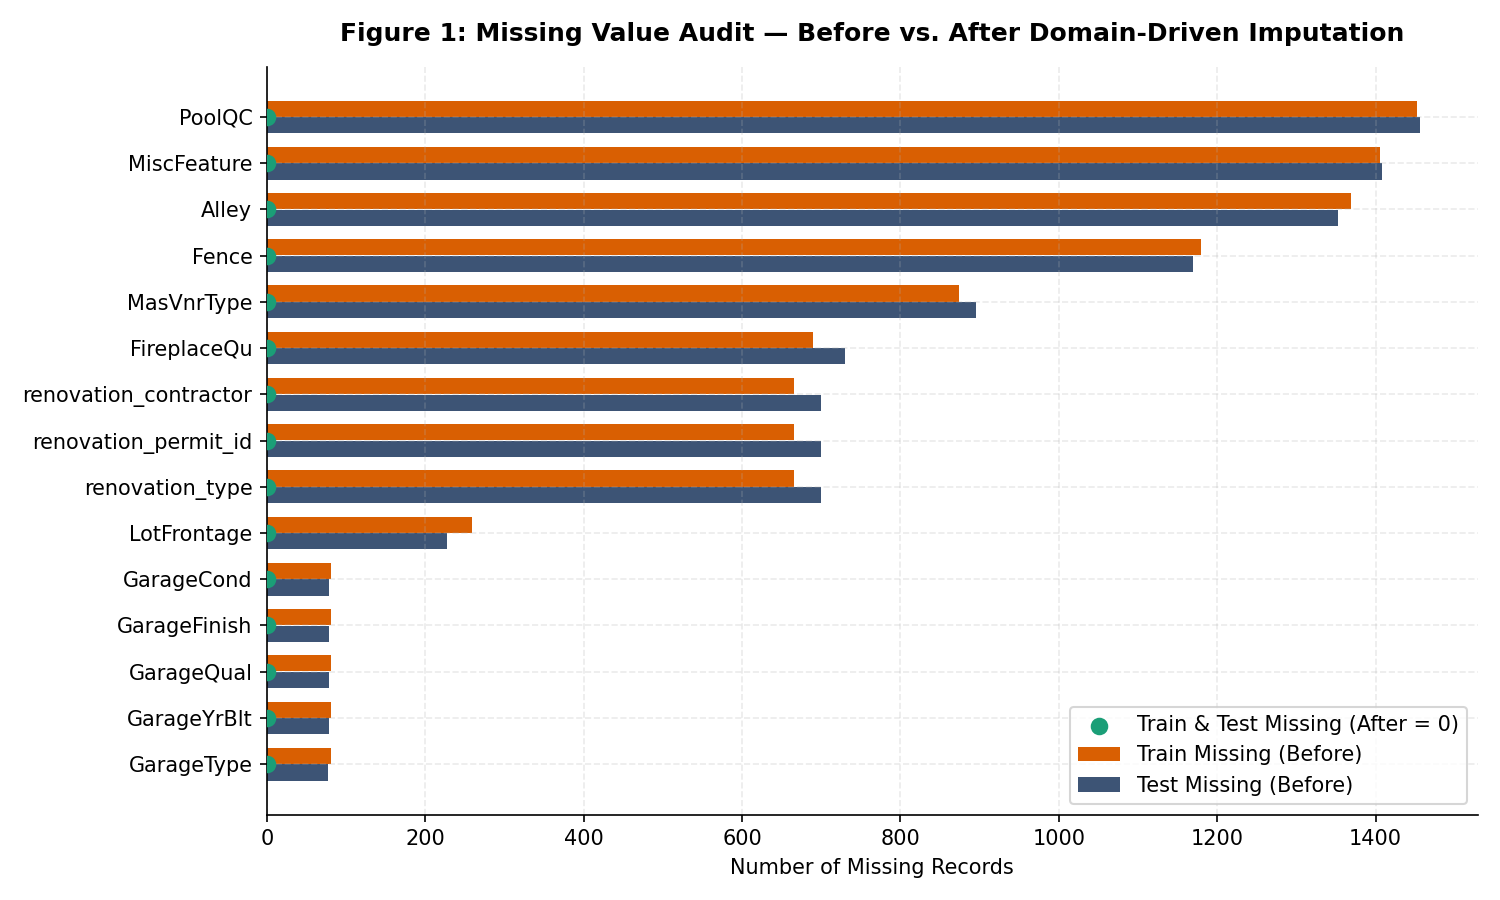

In [4]:
print('=== Deterministic Data-Entry & Logic Fixes ===')
display(results['error_correction_log'])

print('\n=== Missing Value Audit (Before vs. After) ===')
display(results['missing_value_audit'])

display(Image(filename=f'{figures_dir}/fig1_missing_values_before_after.png'))

## 4. Outlier & Leverage Treatment (Before vs. After)
Non-representative partial-sale leverage outliers in `Edwards` (`Id 524` and `Id 1299`, where `GrLivArea > 4,000 sq ft` sold below `$185,000`) are removed from the training split, while extreme right-tail acreage/basement values (`LotArea`, `TotalBsmtSF`) are winsorized using training-set 99.5th percentile thresholds.

=== Removed Training Leverage Outliers ===


,Id,Neighborhood,GrLivArea,TotalBsmtSF,OverallQual,SalePrice,SaleCondition,action
523,524,Edwards,4676,3138,10,184750,Partial,Removed from training set (non-representative ...
1298,1299,Edwards,5642,6110,10,160000,Partial,Removed from training set (non-representative ...



=== Outlier & Winsorization Impact Comparison ===


,feature,treatment,upper_threshold,train_capped_rows,test_capped_rows,train_max_before,train_max_after,train_skew_before,train_skew_after,test_max_before,test_max_after
0,GrLivArea (leverage filter),"Drop train rows with GrLivArea > 4,000 & SaleP...",4000.00,2,0,5642.0,4476.00,1.367,1.011,5095.0,5095.00
1,LotArea,Winsorize at train 99.5th percentile,53192.80,8,1,215245.0,53192.80,12.574,3.814,56600.0,53192.80
2,TotalBsmtSF,Winsorize at train 99.5th percentile,2374.33,8,11,3206.0,2374.33,0.512,0.307,5095.0,2374.33


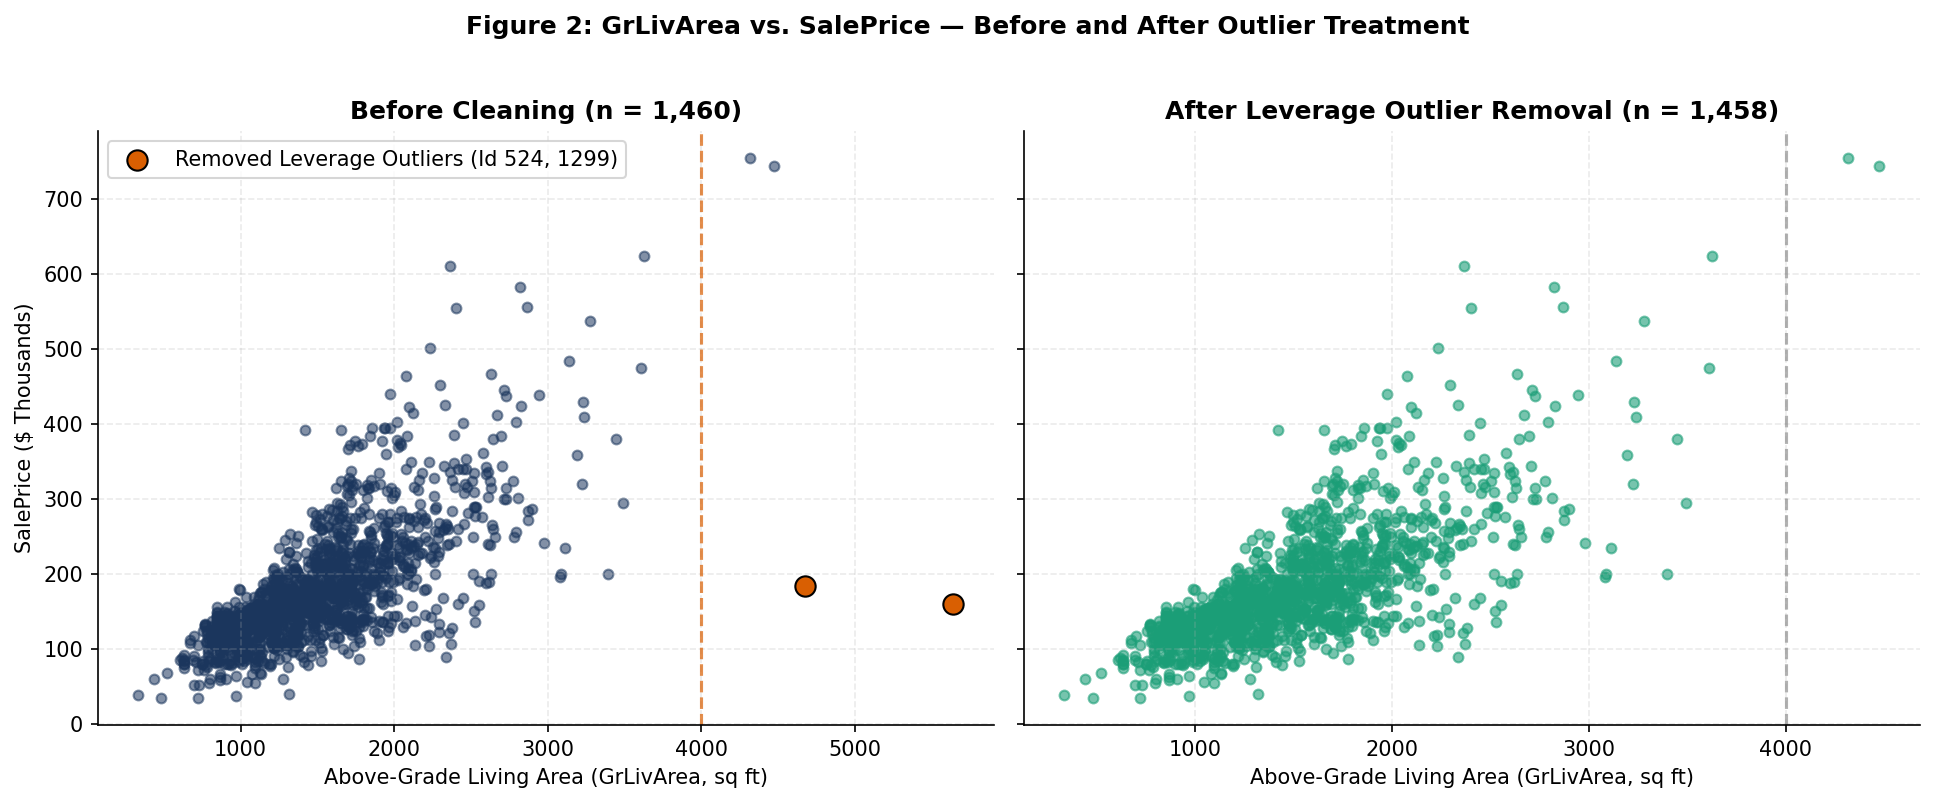

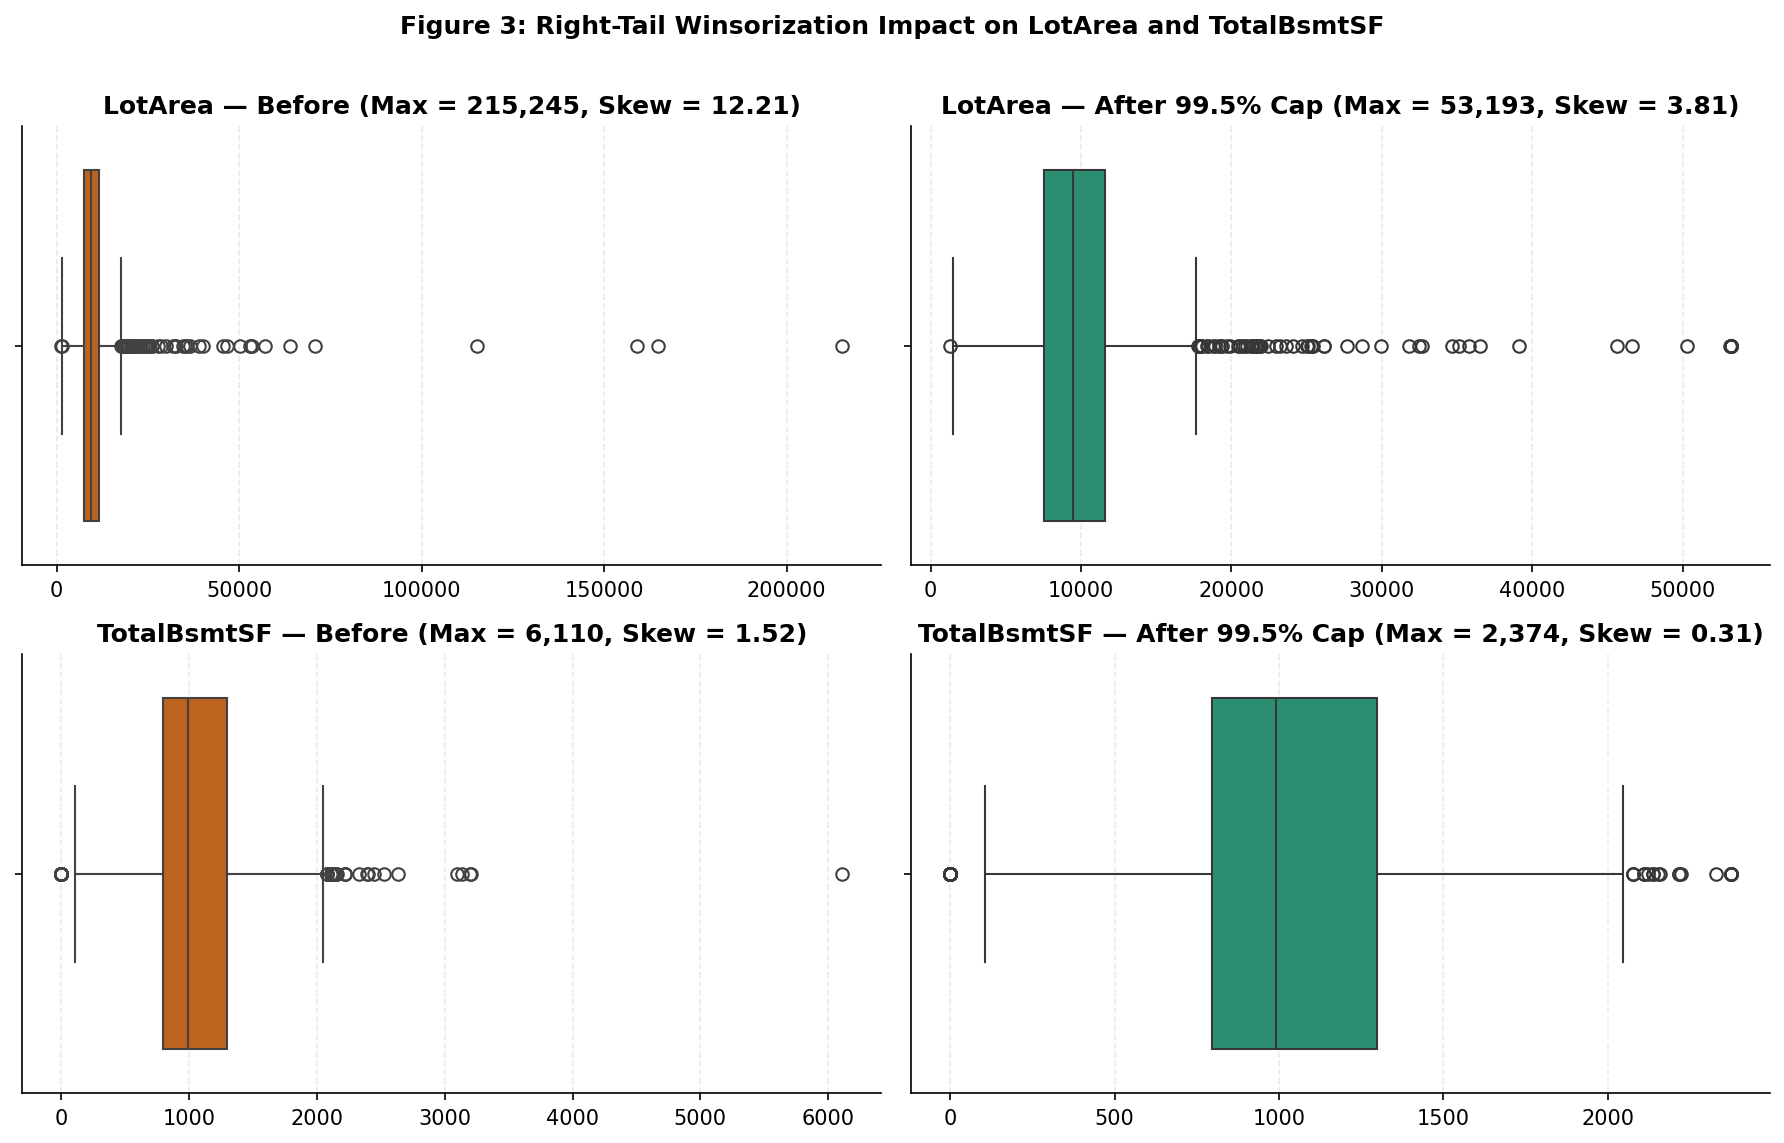

In [5]:
print('=== Removed Training Leverage Outliers ===')
display(results['removed_outliers'])

print('\n=== Outlier & Winsorization Impact Comparison ===')
display(results['outlier_summary'])

display(Image(filename=f'{figures_dir}/fig2_grlivarea_outlier_comparison.png'))
display(Image(filename=f'{figures_dir}/fig3_winsorization_boxplots.png'))